In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv('Exam_Score_Prediction.csv')

In [ ]:
df.head()

,student_id,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
0,1,17,male,diploma,2.78,92.9,yes,7.4,poor,coaching,low,hard,58.9
1,2,23,other,bca,3.37,64.8,yes,4.6,average,online videos,medium,moderate,54.8
2,3,22,male,b.sc,7.88,76.8,yes,8.5,poor,coaching,high,moderate,90.3
3,4,20,other,diploma,0.67,48.4,yes,5.8,average,online videos,low,moderate,29.7
4,5,20,female,diploma,0.89,71.6,yes,9.8,poor,coaching,low,moderate,43.7


In [ ]:
print('Number of rows:', df.shape[0])
print('Number of columns:', df.shape[1])


Number of rows: 20000
Number of columns: 13


In [ ]:
df.columns

Index(['student_id', 'age', 'gender', 'course', 'study_hours',
       'class_attendance', 'internet_access', 'sleep_hours', 'sleep_quality',
       'study_method', 'facility_rating', 'exam_difficulty', 'exam_score'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   student_id        20000 non-null  int64  
 1   age               20000 non-null  int64  
 2   gender            20000 non-null  object 
 3   course            20000 non-null  object 
 4   study_hours       20000 non-null  float64
 5   class_attendance  20000 non-null  float64
 6   internet_access   20000 non-null  object 
 7   sleep_hours       20000 non-null  float64
 8   sleep_quality     20000 non-null  object 
 9   study_method      20000 non-null  object 
 10  facility_rating   20000 non-null  object 
 11  exam_difficulty   20000 non-null  object 
 12  exam_score        20000 non-null  float64
dtypes: float64(4), int64(2), object(7)
memory usage: 2.0+ MB


In [ ]:
df.describe()

,student_id,age,study_hours,class_attendance,sleep_hours,exam_score
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.00000,20000.000000
mean,10000.504600,20.473300,4.007604,70.017365,7.00856,62.513225
std,5773.654959,2.284458,2.308313,17.282262,1.73209,18.908491
min,1.000000,17.000000,0.080000,40.600000,4.10000,19.599000
25%,5000.750000,18.000000,2.000000,55.100000,5.50000,48.800000
50%,10000.500000,20.000000,4.040000,69.900000,7.00000,62.600000
75%,15000.250000,22.000000,6.000000,85.000000,8.50000,76.300000
max,20001.000000,24.000000,7.910000,99.400000,9.90000,100.000000


In [ ]:
df.isnull().sum()

,0
student_id,0
age,0
gender,0
course,0
study_hours,0
class_attendance,0
internet_access,0
sleep_hours,0
sleep_quality,0
study_method,0


In [ ]:
df.isna().sum()

,0
student_id,0
age,0
gender,0
course,0
study_hours,0
class_attendance,0
internet_access,0
sleep_hours,0
sleep_quality,0
study_method,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.columns

Index(['student_id', 'age', 'gender', 'course', 'study_hours',
       'class_attendance', 'internet_access', 'sleep_hours', 'sleep_quality',
       'study_method', 'facility_rating', 'exam_difficulty', 'exam_score'],
      dtype='object')

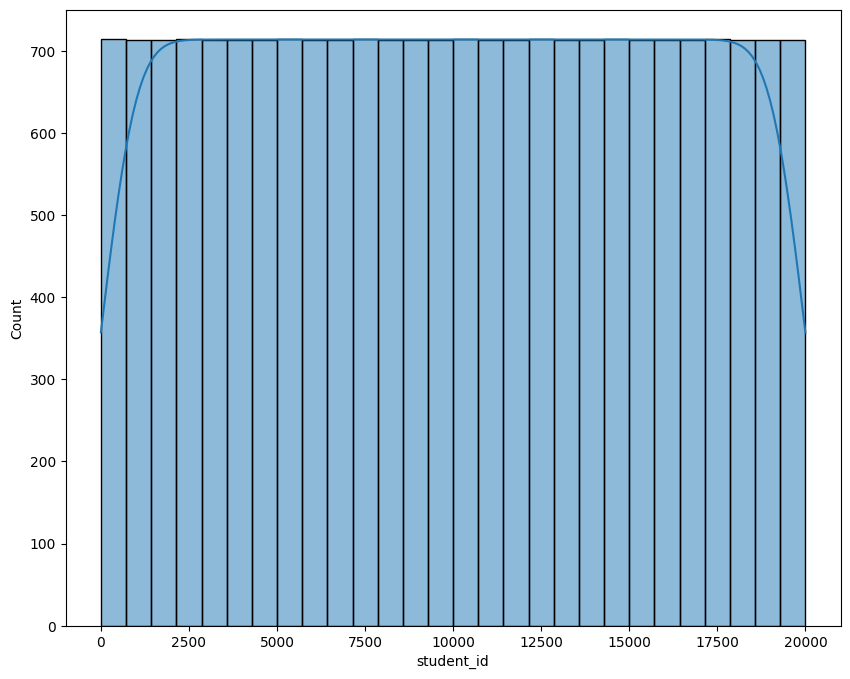

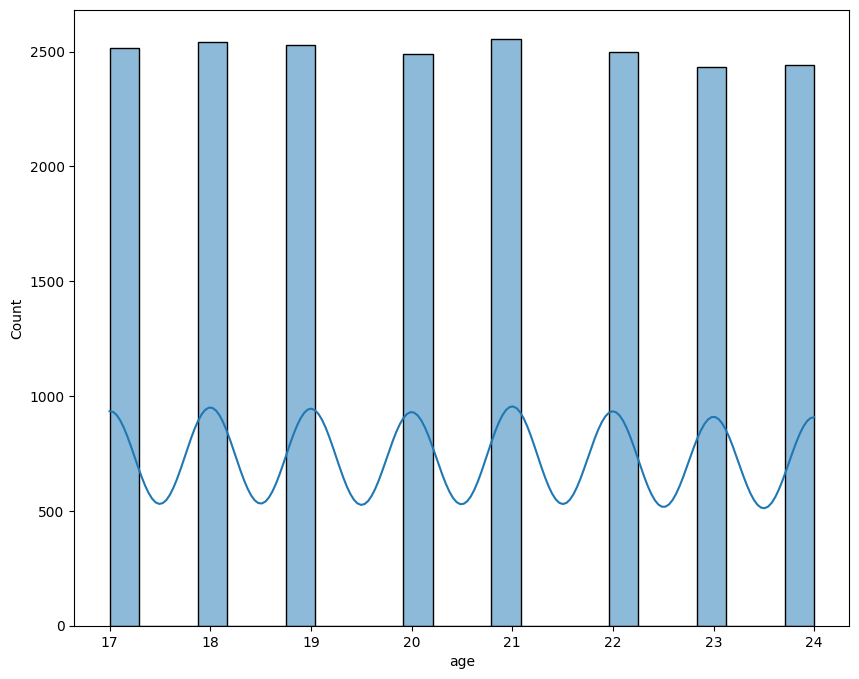

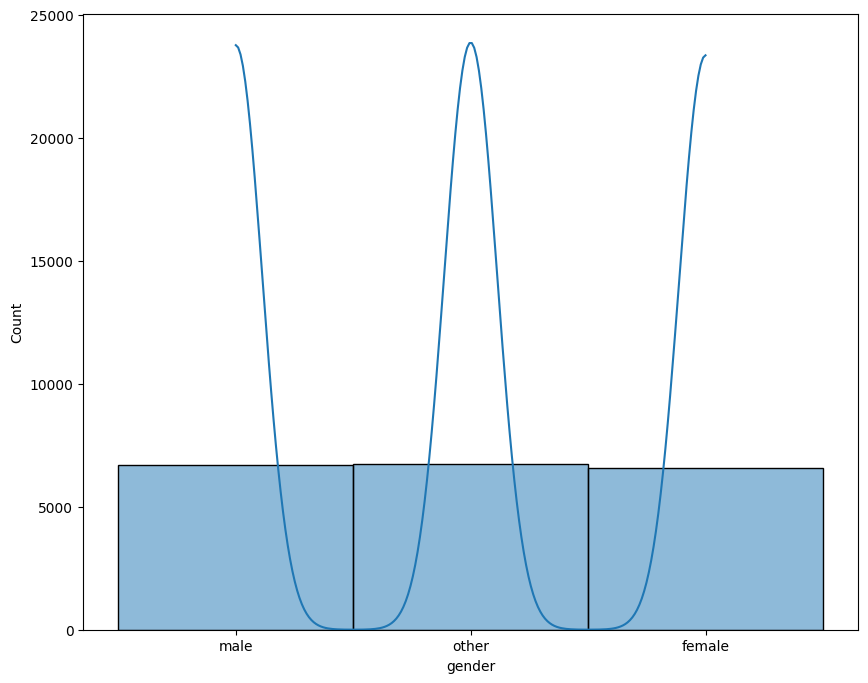

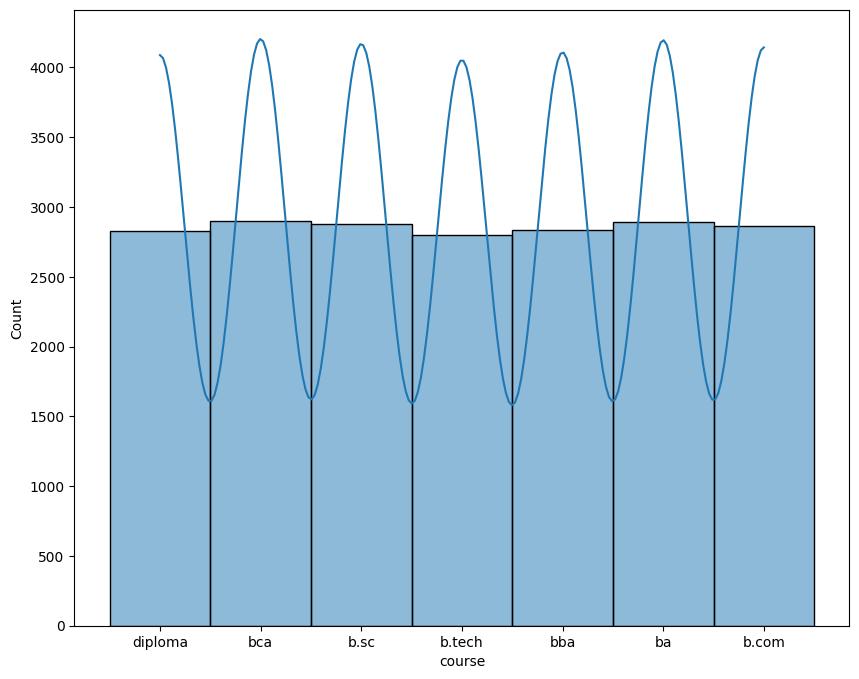

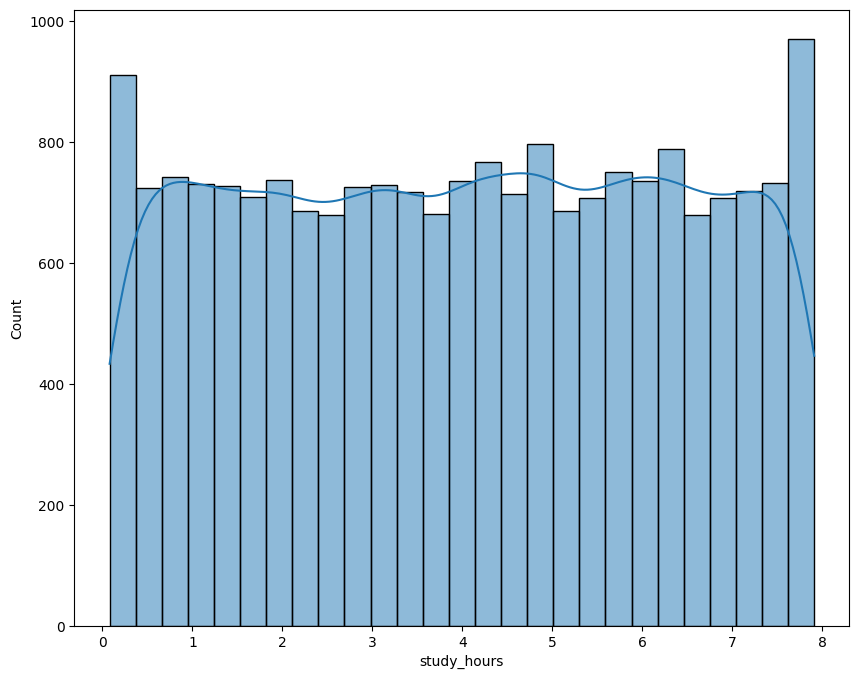

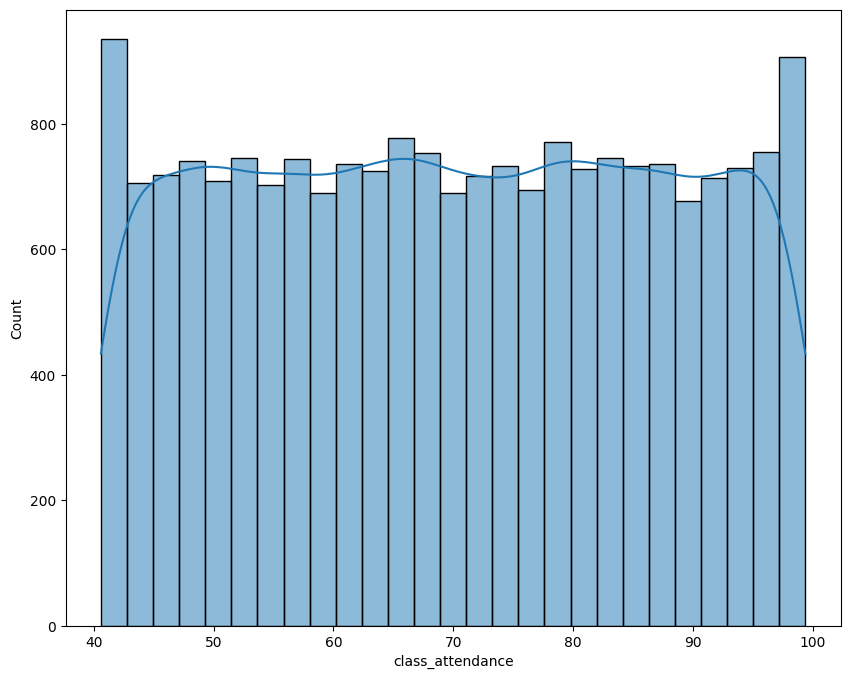

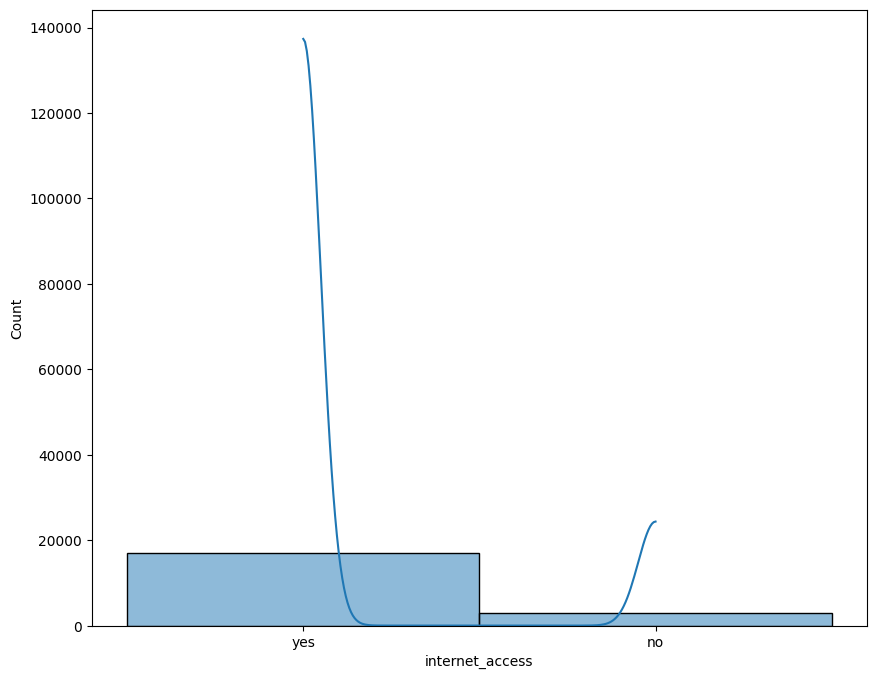

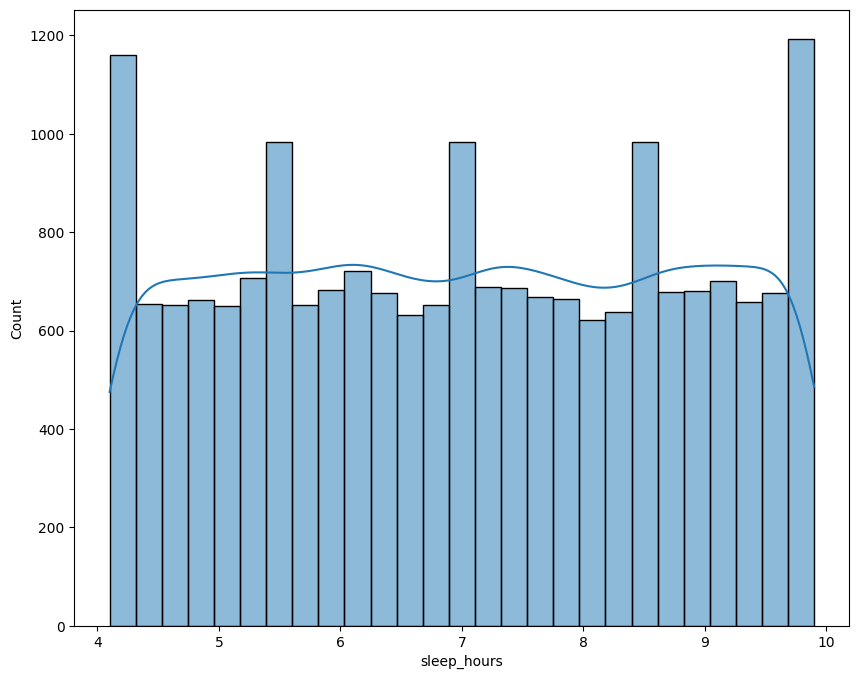

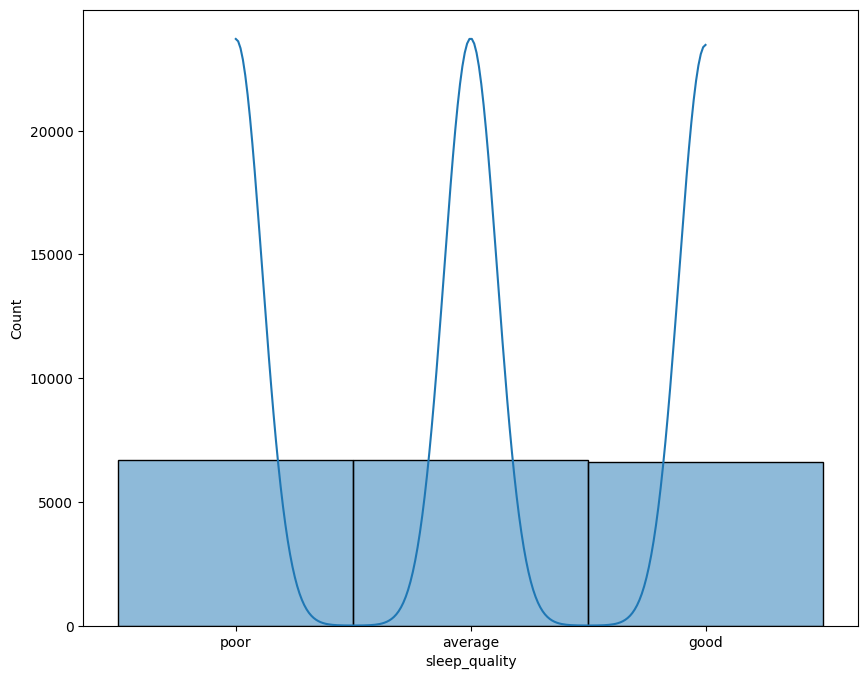

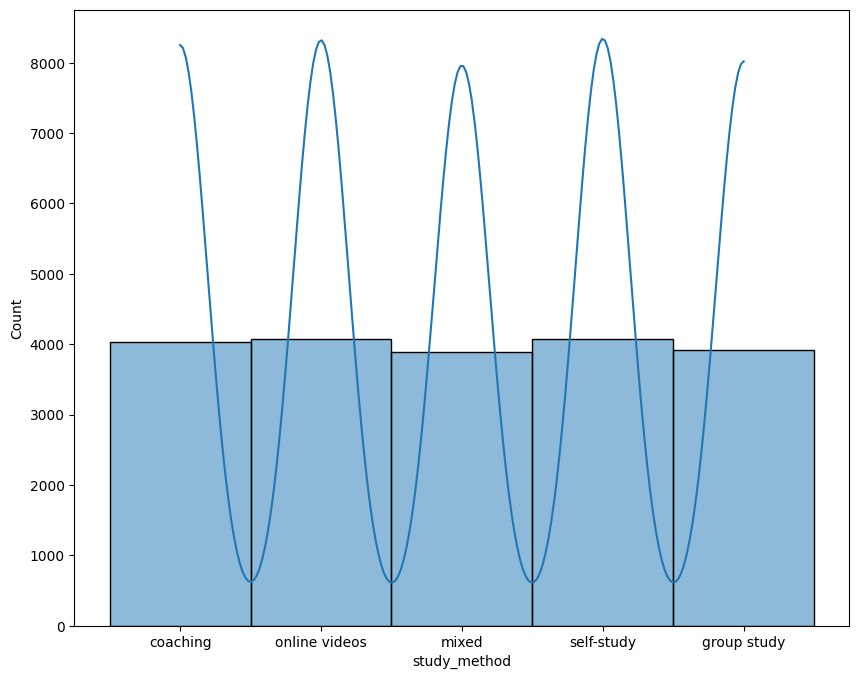

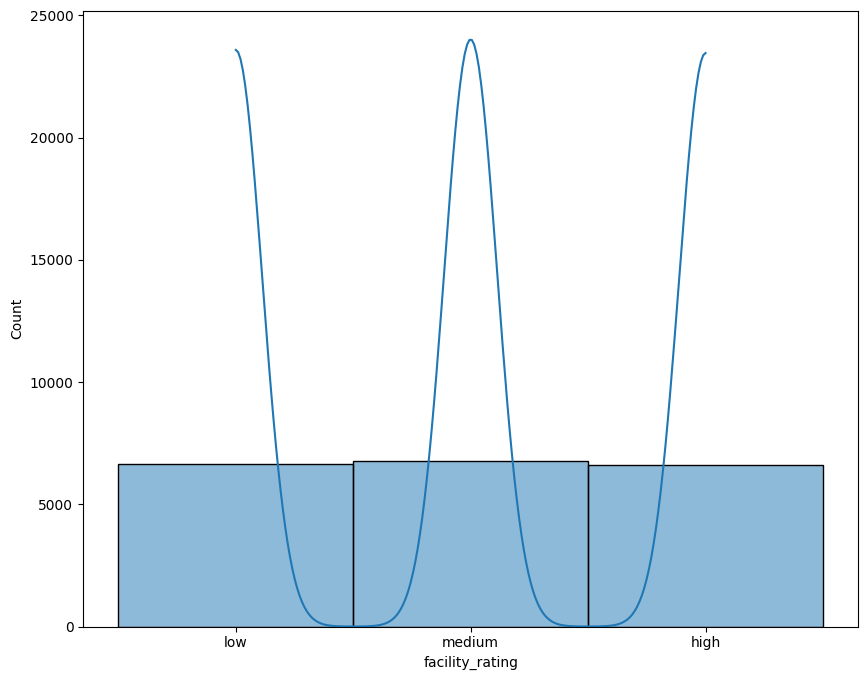

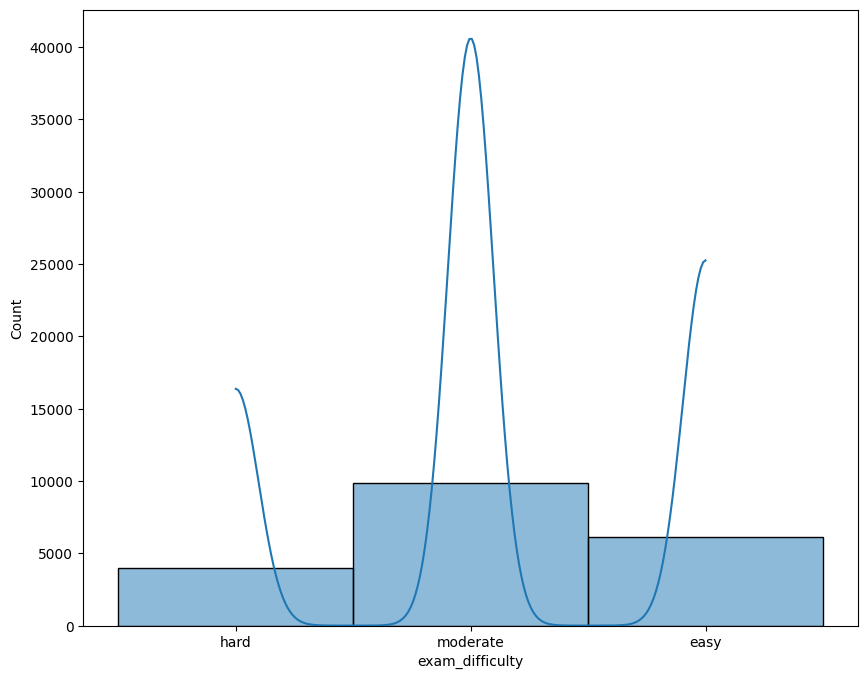

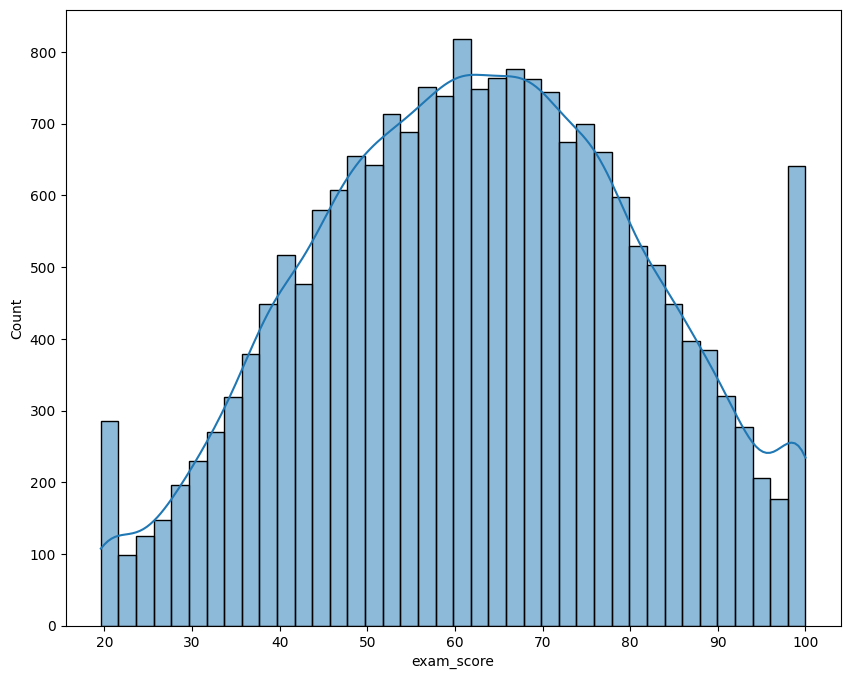

In [ ]:
for i in df.columns:
  plt.figure(figsize = (10,8))
  sns.histplot(df[i], kde=True)
  plt.show()


In [ ]:
df.columns


Index(['student_id', 'age', 'gender', 'course', 'study_hours',
       'class_attendance', 'internet_access', 'sleep_hours', 'sleep_quality',
       'study_method', 'facility_rating', 'exam_difficulty', 'exam_score'],
      dtype='object')

In [ ]:
num_cols = ['age','study_hours','class_attendance','sleep_hours','exam_score']
df_num_col = df[num_cols]

<Axes: >

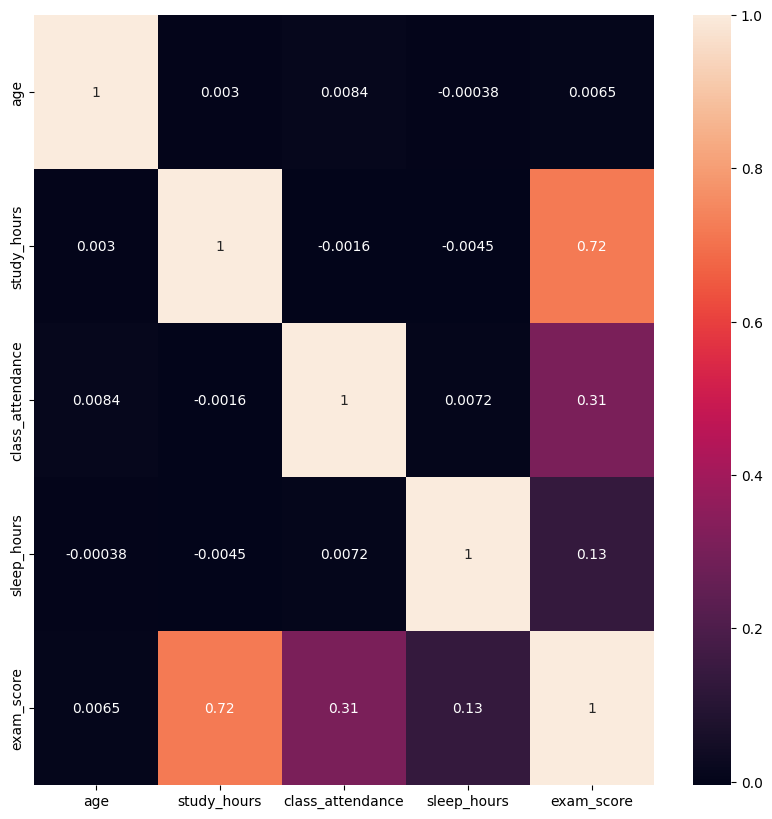

In [ ]:
plt.figure(figsize=(10,10))
sns.heatmap(df_num_col.corr(), annot=True)

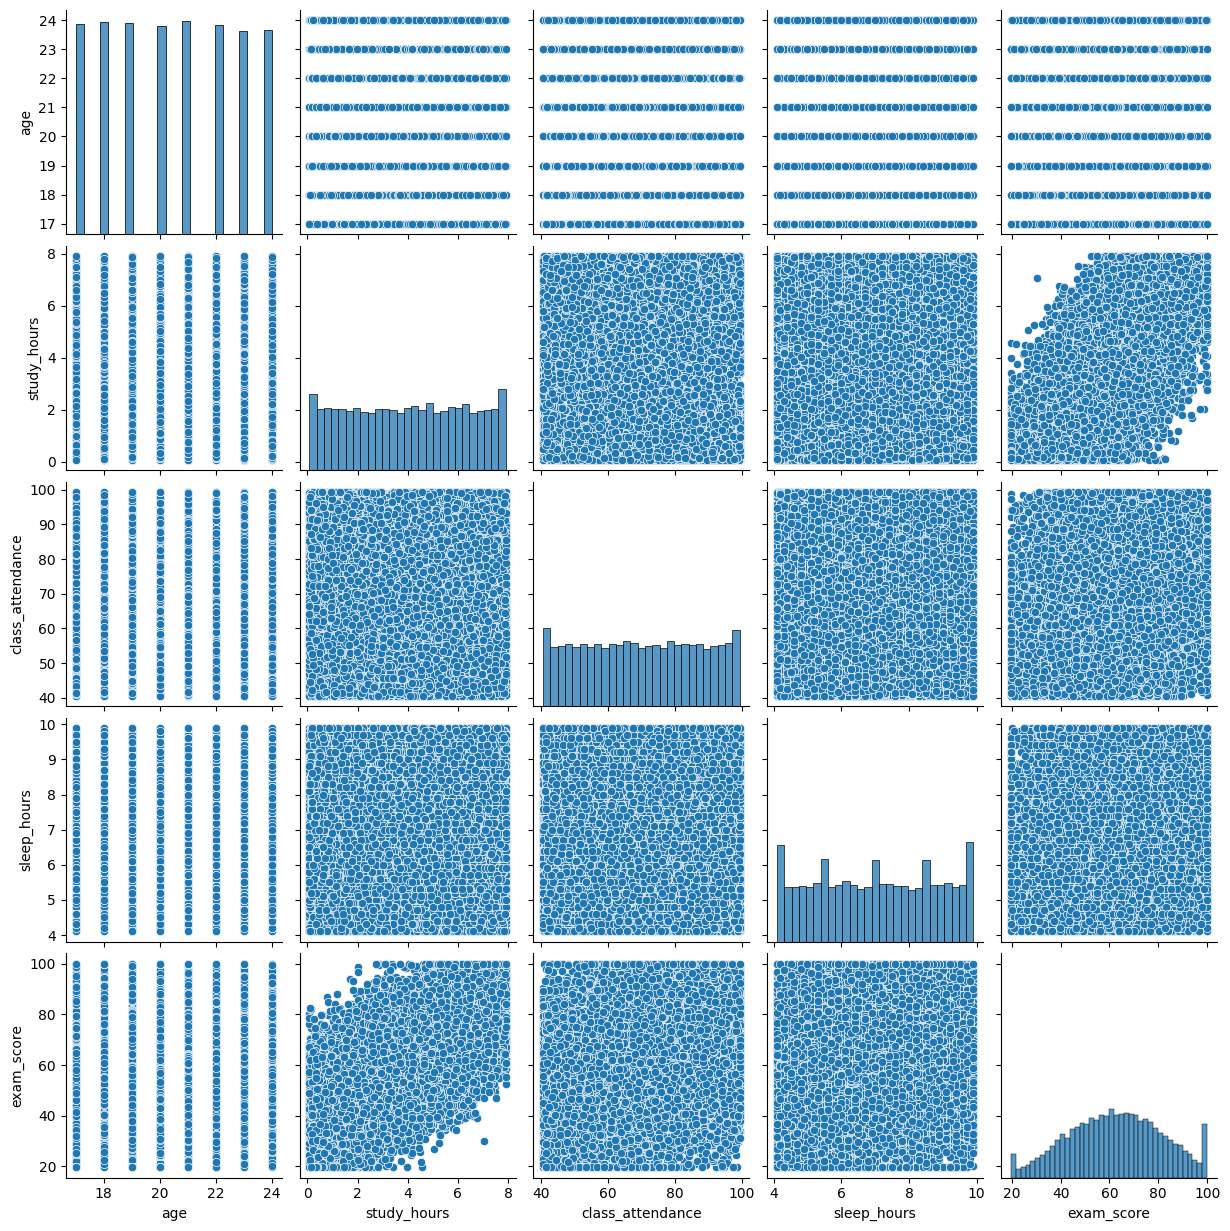

In [ ]:
sns.pairplot(df_num_col)

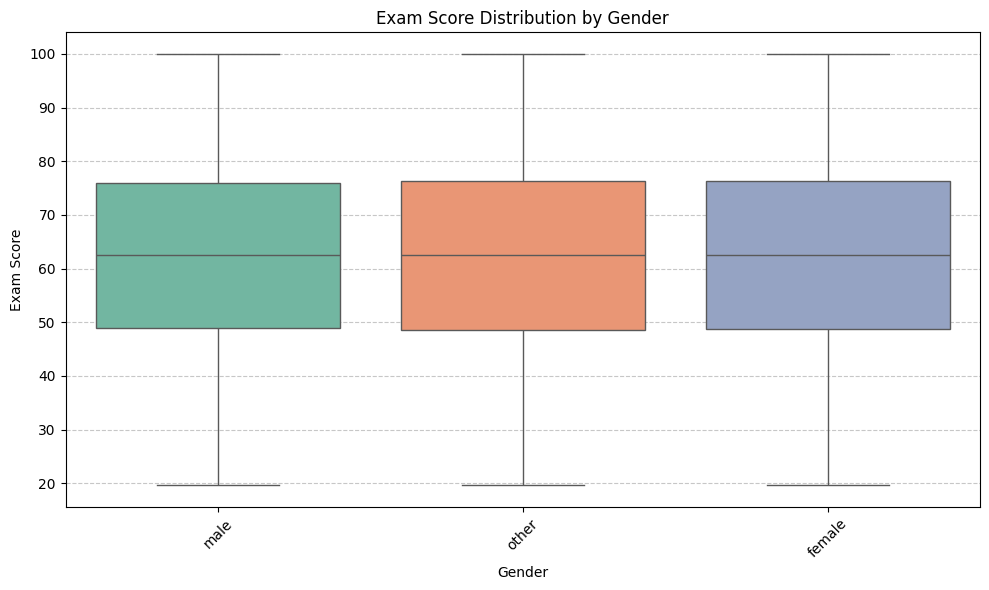

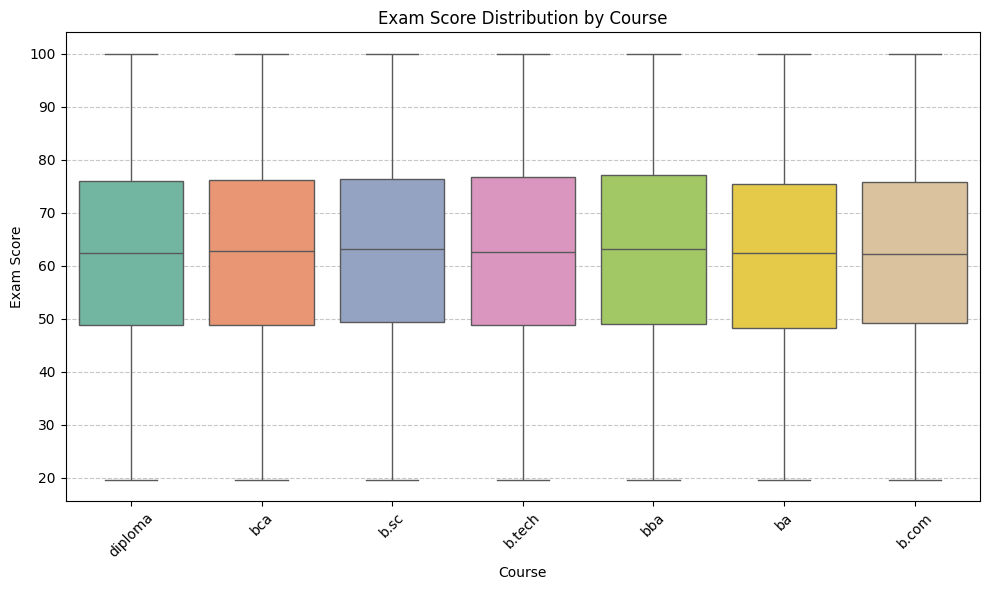

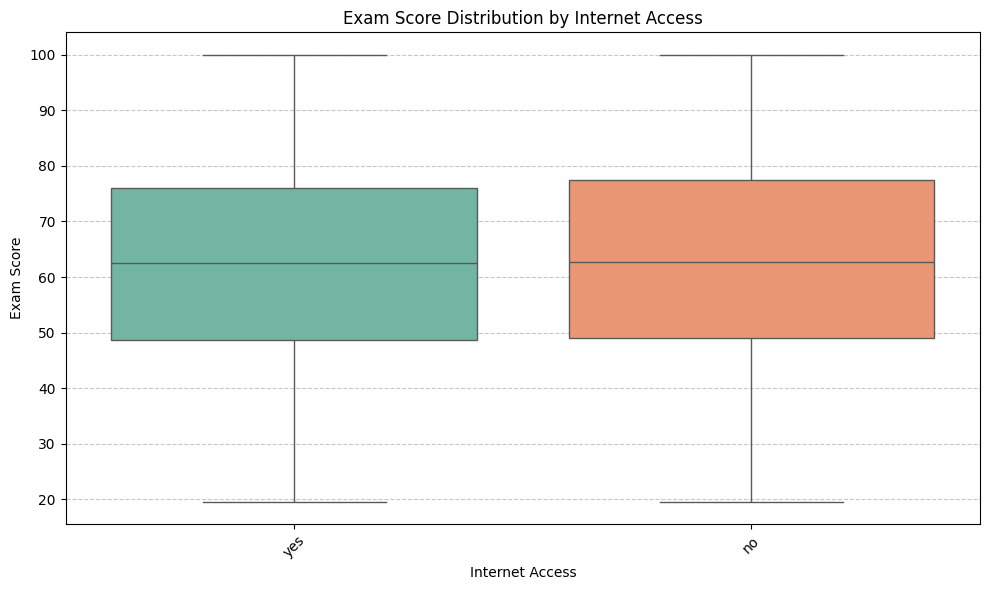

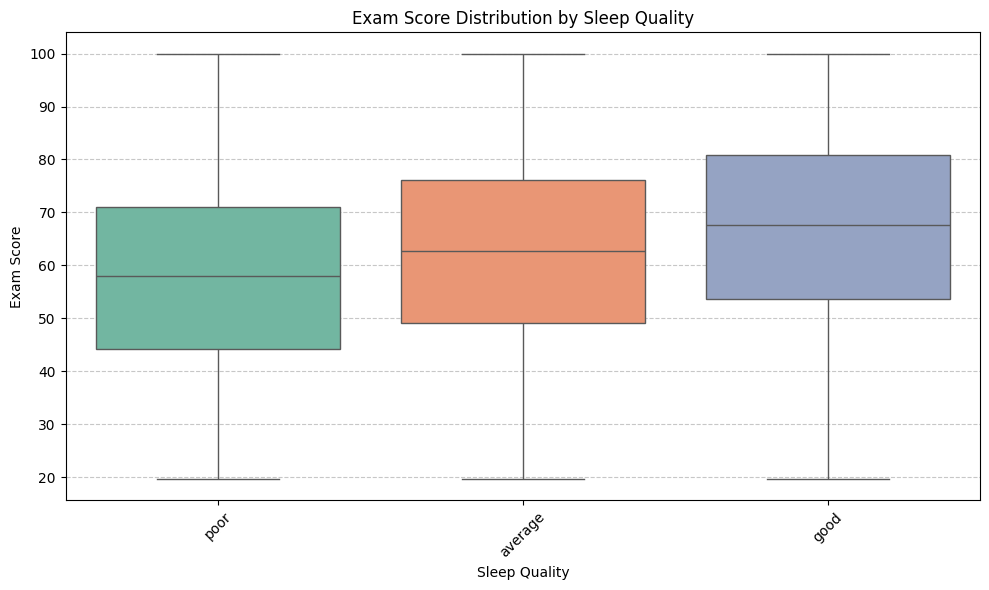

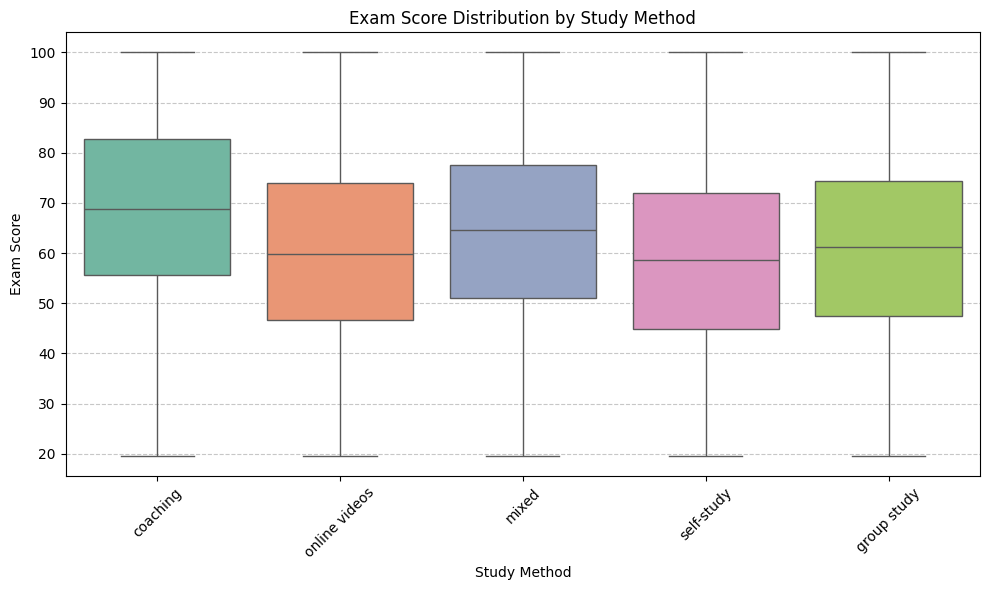

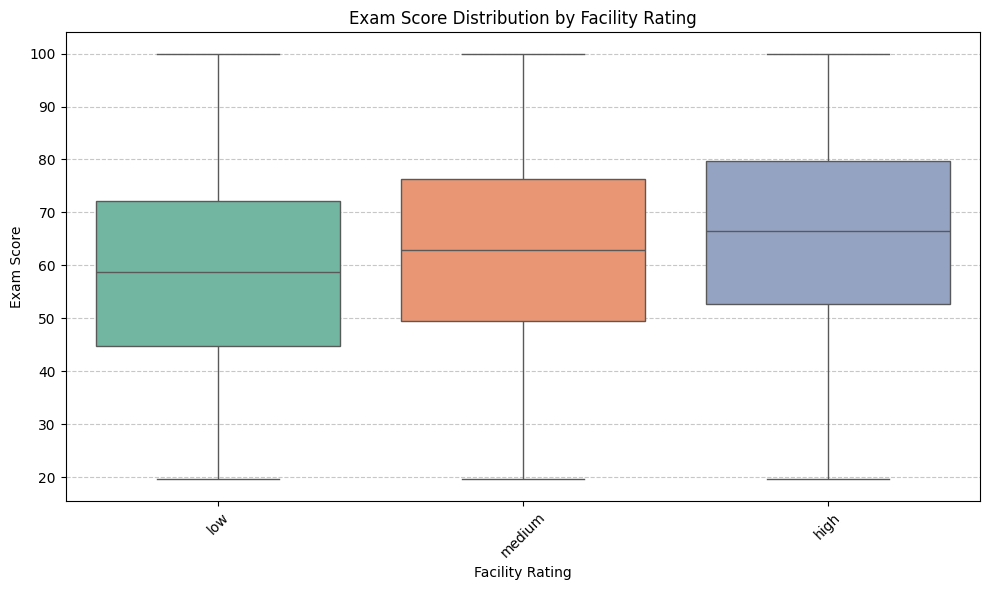

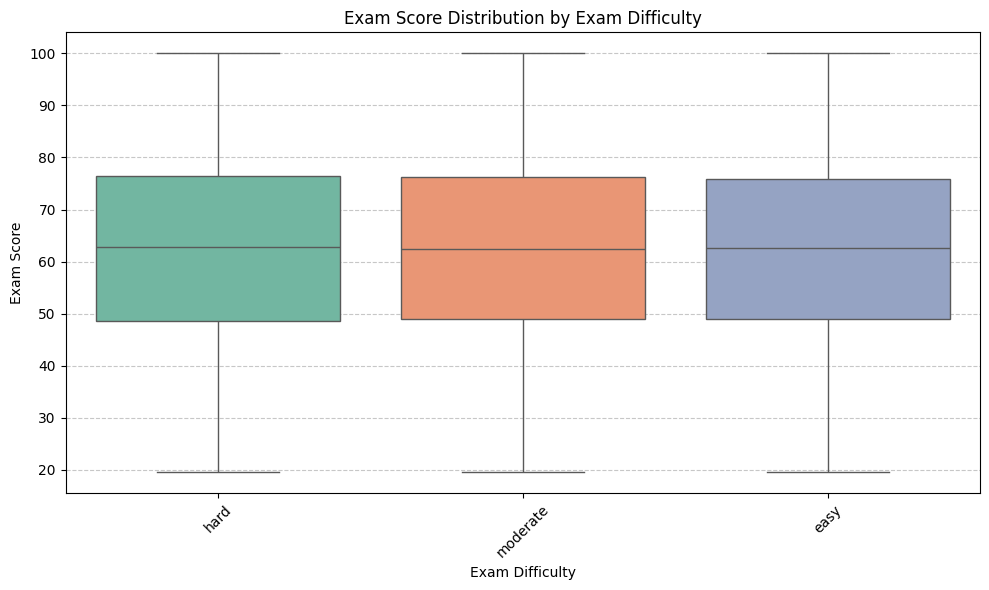

In [ ]:


# Identify categorical columns
cat_cols = ['gender', 'course', 'internet_access', 'sleep_quality', 'study_method', 'facility_rating', 'exam_difficulty']

# Plot the relationship between each categorical feature and exam_score
for col in cat_cols:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=col, y='exam_score', data=df, palette='Set2')
    plt.title(f'Exam Score Distribution by {col.replace("_", " ").title()}')
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel('Exam Score')
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

In [ ]:
import scipy.stats as stats

# Define the list of features to test against exam_score (including age)
features_to_test = ['age', 'gender', 'course', 'internet_access', 'sleep_quality', 'study_method', 'facility_rating', 'exam_difficulty']

results = []

for col in features_to_test:
    # Group exam scores by the category values
    groups = [group['exam_score'].values for name, group in df.groupby(col)]

    # Perform One-Way ANOVA
    f_stat, p_val = stats.f_oneway(*groups)

    results.append({
        'Feature': col,
        'F-Statistic': f_stat,
        'p-value': p_val,
        'Significant (alpha=0.05)': 'Yes' if p_val < 0.05 else 'No'
    })

# Convert results to DataFrame and display
anova_df = pd.DataFrame(results)
display(anova_df)

,Feature,F-Statistic,p-value,Significant (alpha=0.05)
0,age,0.314983,9.476259e-01,No
1,gender,0.190609,8.264568e-01,No
2,course,0.614432,7.189976e-01,No
3,internet_access,1.224987,2.683976e-01,No
4,sleep_quality,411.793336,5.560728e-176,Yes
5,study_method,180.526693,3.198667e-152,Yes
6,facility_rating,273.766437,5.050711e-118,Yes
7,exam_difficulty,0.236966,7.890206e-01,No


In [ ]:
from sklearn.preprocessing import LabelEncoder

# Make a copy of the dataframe to keep original intact
df_encoded = df.copy()

# Initialize LabelEncoder
le = LabelEncoder()

# Identify categorical columns to encode
# We exclude 'student_id' (identifier) and 'exam_score' (target variable)
categorical_cols = ['gender', 'course', 'internet_access', 'sleep_quality', 'study_method', 'facility_rating', 'exam_difficulty']

# Apply LabelEncoder on each categorical column
for col in categorical_cols:
    df_encoded[col] = le.fit_transform(df_encoded[col])

# Display the head of the updated DataFrame
display(df_encoded.head())

,student_id,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
0,1,17,1,6,2.78,92.9,1,7.4,2,0,1,1,58.9
1,2,23,2,5,3.37,64.8,1,4.6,0,3,2,2,54.8
2,3,22,1,1,7.88,76.8,1,8.5,2,0,0,2,90.3
3,4,20,2,6,0.67,48.4,1,5.8,0,3,1,2,29.7
4,5,20,0,6,0.89,71.6,1,9.8,2,0,1,2,43.7


In [ ]:
x = df_encoded.drop(['exam_score','student_id','gender','exam_difficulty'], axis=1)
y = df_encoded['exam_score']


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

In [ ]:
model = DecisionTreeRegressor()
model.fit(X_train, y_train)

DecisionTreeRegressor()

In [ ]:
# Generate predictions using the test dataset
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Print the results
print(f"Decision Tree Regressor Evaluation Metrics:")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2 Score): {r2:.4f}")

Decision Tree Regressor Evaluation Metrics:
Mean Squared Error (MSE): 219.4449
Root Mean Squared Error (RMSE): 14.8137
R-squared (R2 Score): 0.3921


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 10, 20, 50],
    'min_samples_leaf': [1, 5, 10, 20]
}

grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
best_model = grid_search.best_estimator_

print("Best Hyperparameters:", best_params)

y_pred_opt = best_model.predict(X_test)
mse_opt = mean_squared_error(y_test, y_pred_opt)
rmse_opt = np.sqrt(mse_opt)
r2_opt = r2_score(y_test, y_pred_opt)

print(f"\nOptimized Decision Tree Regressor Evaluation Metrics:")
print(f"Mean Squared Error (MSE): {mse_opt:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_opt:.4f}")
print(f"R-squared (R2 Score): {r2_opt:.4f}")

Best Hyperparameters: {'max_depth': 10, 'min_samples_leaf': 20, 'min_samples_split': 50}

Optimized Decision Tree Regressor Evaluation Metrics:
Mean Squared Error (MSE): 121.7475
Root Mean Squared Error (RMSE): 11.0339
R-squared (R2 Score): 0.6627


In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Initialize and train the Random Forest Regressor with default parameters
rf_model = RandomForestRegressor(random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluate the Random Forest model
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print(f"Random Forest Regressor Evaluation Metrics:")
print(f"Mean Squared Error (MSE): {mse_rf:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_rf:.4f}")
print(f"R-squared (R2 Score): {r2_rf:.4f}")

Random Forest Regressor Evaluation Metrics:
Mean Squared Error (MSE): 109.1241
Root Mean Squared Error (RMSE): 10.4462
R-squared (R2 Score): 0.6977


In [ ]:
from sklearn.ensemble import AdaBoostRegressor

ada_model = AdaBoostRegressor(random_state=42)
ada_model.fit(X_train, y_train)

y_pred_ada = ada_model.predict(X_test)

mse_ada = mean_squared_error(y_test, y_pred_ada)
rmse_ada = np.sqrt(mse_ada)
r2_ada = r2_score(y_test, y_pred_ada)

print(f"AdaBoost Regressor Evaluation Metrics:")
print(f"Mean Squared Error (MSE): {mse_ada:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_ada:.4f}")
print(f"R-squared (R2 Score): {r2_ada:.4f}")

AdaBoost Regressor Evaluation Metrics:
Mean Squared Error (MSE): 118.3619
Root Mean Squared Error (RMSE): 10.8794
R-squared (R2 Score): 0.6721


In [ ]:
from xgboost import XGBRegressor

# Initialize and train the XGBoost Regressor with default parameters
xgb_model = XGBRegressor(random_state=42, n_jobs=-1)
xgb_model.fit(X_train, y_train)

# Make predictions
y_pred_xgb = xgb_model.predict(X_test)

# Evaluate the XGBoost model
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

print(f"XGBoost Regressor Evaluation Metrics:")
print(f"Mean Squared Error (MSE): {mse_xgb:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_xgb:.4f}")
print(f"R-squared (R2 Score): {r2_xgb:.4f}")

XGBoost Regressor Evaluation Metrics:
Mean Squared Error (MSE): 108.9748
Root Mean Squared Error (RMSE): 10.4391
R-squared (R2 Score): 0.6981


In [ ]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor

xgb_param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 200, 300],
    'subsample': [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    estimator=XGBRegressor(random_state=42, n_jobs=-1),
    param_grid=xgb_param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

xgb_grid.fit(X_train, y_train)

best_xgb_params = xgb_grid.best_params_
best_xgb_model = xgb_grid.best_estimator_

print("Best Hyperparameters for XGBoost:", best_xgb_params)

y_pred_xgb_opt = best_xgb_model.predict(X_test)

mse_xgb_opt = mean_squared_error(y_test, y_pred_xgb_opt)
rmse_xgb_opt = np.sqrt(mse_xgb_opt)
r2_xgb_opt = r2_score(y_test, y_pred_xgb_opt)

print(f"\nOptimized XGBoost Regressor Evaluation Metrics:")
print(f"Mean Squared Error (MSE): {mse_xgb_opt:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_xgb_opt:.4f}")
print(f"R-squared (R2 Score): {r2_xgb_opt:.4f}")

Best Hyperparameters for XGBoost: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.8}

Optimized XGBoost Regressor Evaluation Metrics:
Mean Squared Error (MSE): 96.9695
Root Mean Squared Error (RMSE): 9.8473
R-squared (R2 Score): 0.7314


In [ ]:
import pickle

# Define the filename for saving the model
model_filename = 'optimized_xgb_model.pkl'

# Save the best XGBoost model to a pickle file
with open(model_filename, 'wb') as file:
    pickle.dump(best_xgb_model, file)

print(f"Successfully saved the model as '{model_filename}'!")

Successfully saved the model as 'optimized_xgb_model.pkl'!
